In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import transformers
from transformers import pipeline
import numpy as np
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import nltk
from nltk.tokenize import word_tokenize
nltk.download("stopwords")
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn import metrics
from itertools import chain
from nltk import NaiveBayesClassifier

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ahesan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Load Data

In [36]:
data = pd.read_csv("03 book-reviews-sample.csv")
data.head(10)

,index,reviewText,rating
0,11494,Clean and funny. A bit busy with all the diffe...,3
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4
2,1463,Good thing that this is a free story. I read i...,1
3,10342,"Action, action, action! Equipment keeps gettin...",4
4,5256,this was hands down the worse book i have ever...,1
5,7277,"Great book packed full with fast cars , crazy ...",4
6,9781,I enjoyed the reader's digest very much. If I ...,4
7,4583,This series has been good and I look forward t...,5
8,9797,I just could not get into this book.I all ways...,1
9,895,it was good to see where Dan and Elle was. And...,4


In [37]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   index       100 non-null    int64 
 1   reviewText  100 non-null    object
 2   rating      100 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 2.5+ KB


Clean Data

In [38]:
data["lowercase"] = data["reviewText"].apply(lambda x: x.lower())

In [42]:
data['no_punc'] = data["lowercase"].apply(lambda x: re.sub(r"[^\w\s]", "",x))

Rule Based Sentiment with VADER

In [46]:
vader_sentiment = SentimentIntensityAnalyzer()
data["vader_sentiment_score"] = data['no_punc'].apply(lambda x: vader_sentiment.polarity_scores(x)['compound'] )

In [47]:
bins =[-1, -0.1,0.1,1]
names =['negative', 'neutral', 'positive']
data['vader_sentiment_labels'] = pd.cut(data['vader_sentiment_score'], bins, labels = names)

<Axes: xlabel='vader_sentiment_labels'>

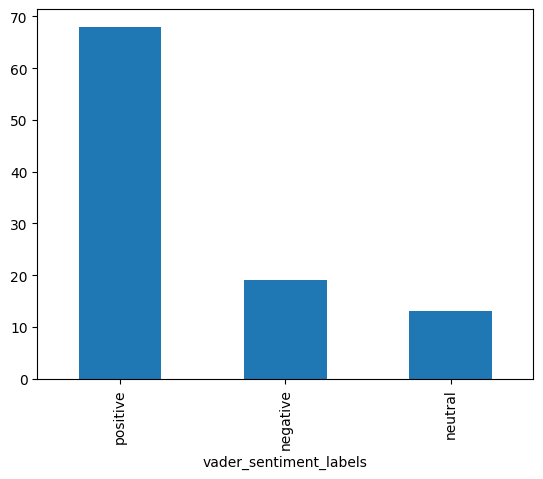

In [50]:
data['vader_sentiment_labels'].value_counts().plot.bar()

Pre Trained Transformer

In [55]:
model_1 = pipeline("sentiment-analysis", model="finiteautomata/bertweet-base-sentiment-analysis")

emoji is not installed, thus not converting emoticons or emojis into text. Install emoji: pip3 install emoji==0.6.0
Device set to use cpu


In [56]:
transformers_label = []
for review in data['no_punc']:
    sentiment_list = model_1(review)
    sentiment_label = [sent['label'] for sent in sentiment_list]
    transformers_label.append(sentiment_label)
data['transformers_label'] = transformers_label
data.head()

,index,reviewText,rating,lowercase,no_punc,vader_sentiment_score,vader_sentiment_labels,transformers_label
0,11494,Clean and funny. A bit busy with all the diffe...,3,clean and funny. a bit busy with all the diffe...,clean and funny a bit busy with all the differ...,0.7684,positive,[POS]
1,984,Alex a sexy hot cop and the PhD candidate. Wha...,4,alex a sexy hot cop and the phd candidate. wha...,alex a sexy hot cop and the phd candidate what...,0.9325,positive,[POS]
2,1463,Good thing that this is a free story. I read i...,1,good thing that this is a free story. i read i...,good thing that this is a free story i read it...,0.6740,positive,[NEG]
3,10342,"Action, action, action! Equipment keeps gettin...",4,"action, action, action! equipment keeps gettin...",action action action equipment keeps getting b...,0.6652,positive,[NEG]
4,5256,this was hands down the worse book i have ever...,1,this was hands down the worse book i have ever...,this was hands down the worse book i have ever...,-0.4767,negative,[NEG]


<Axes: xlabel='transformers_label'>

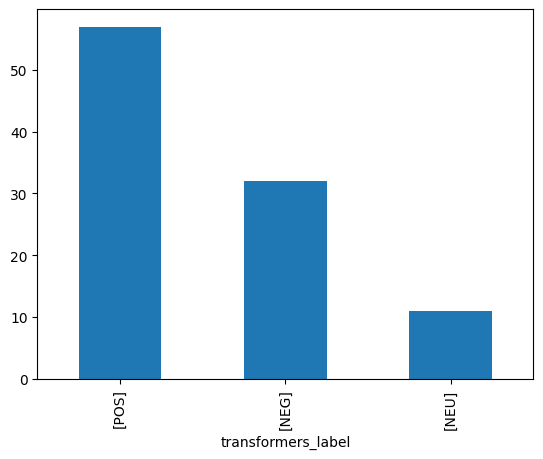

In [57]:
data['transformers_label'].value_counts().plot.bar()